# TVCFormer ? Error Analysis theo th?i gian v? volatility

Notebook t?i s? d?ng `pred.npy` gi?a k? cho c?c prediction length 96, 192, 336, 720; kh?ng hu?n luy?n l?i. Ground truth v? scaler ???c t?i d?ng theo `Dataset_Custom` trong `official/data_provider/data_loader.py` (70% train, 10% validation, 20% test; chu?n h?a StandardScaler fit tr?n train). D? ?o?n ???c ??i v? ??n v? OT ban ??u tr??c khi t?nh sai s?.

Volatility l? rolling standard deviation 30 ng?y c?a log-return OT, bi?t t?i forecast origin (ng?y ngay tr??c b??c d? b?o ??u ti?n). Hai ng??ng Low/Medium/High l? tercile c?a volatility **train + validation**, v? ???c c? ??nh khi ?p d?ng l?n test. Kh?ng d?ng ph?n ph?i volatility hay sai s? test ?? ch?n ng??ng. MSE/MAE nh?m test ???c g?p tr?n c?c forecast origin v? lead t??ng ?ng; c?c ng?y xu?t hi?n ? nhi?u c?a s? forecast n?n ???c t?nh theo t?ng l?n d? b?o.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Resolve repository regardless of notebook working directory.
def find_repo(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "official" / "results").exists() and (p / "experiments" / "datasets" / "exchange_rate.csv").exists():
            return p
    raise FileNotFoundError("Kh?ng t?m th?y repository TVCFormer")

REPO = find_repo()
DATA_PATH = REPO / "experiments" / "datasets" / "exchange_rate.csv"
PRED_DIR = REPO / "official" / "results"
SEQ_LEN = 336
PRED_LENGTHS = [96, 192, 336, 720]
VOL_WINDOW = 30
raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
# C?ng th? t? c?t c?a Dataset_Custom: date, c?c bi?n kh?c, target cu?i.
cols = [c for c in raw.columns if c not in ("date", "OT")] + ["OT"]
raw = raw[["date"] + cols]
n = len(raw); n_train = int(n * .7); n_test = int(n * .2); n_val = n - n_train - n_test
train_end, val_end = n_train, n_train + n_val
print(f"Rows={n:,} | train={n_train:,} | validation={n_val:,} | test={n_test:,}")
print("Prediction arrays:", PRED_DIR)
display(raw.head(3))


Rows=7,588 | train=5,311 | validation=760 | test=1,517
Prediction arrays: d:\TVCFORMER\official\results


,date,0,1,2,3,4,5,6,OT
0,1990-01-01,0.7855,1.6110,0.861698,0.634196,0.211242,0.006838,0.525486,0.5930
1,1990-01-02,0.7818,1.6100,0.861104,0.633513,0.211242,0.006863,0.523972,0.5940
2,1990-01-03,0.7867,1.6293,0.861030,0.648508,0.211242,0.006975,0.526316,0.5973


## T?i d?ng volatility v? ng??ng ch? t? train/validation

Tercile ph?n v? 1/3 v? 2/3 ???c ??c l??ng t? rolling volatility c? ng?y thu?c train ho?c validation. Gi? tr? t?i forecast origin c?a test ???c g?n v?o m?t trong ba nh?m b?ng ??ng hai ng??ng c? ??nh.


Volatility thresholds (train + validation): Low/Medium=0.0053443272; Medium/High=0.0072349746
Test target start row=6071; test window context starts row=5735


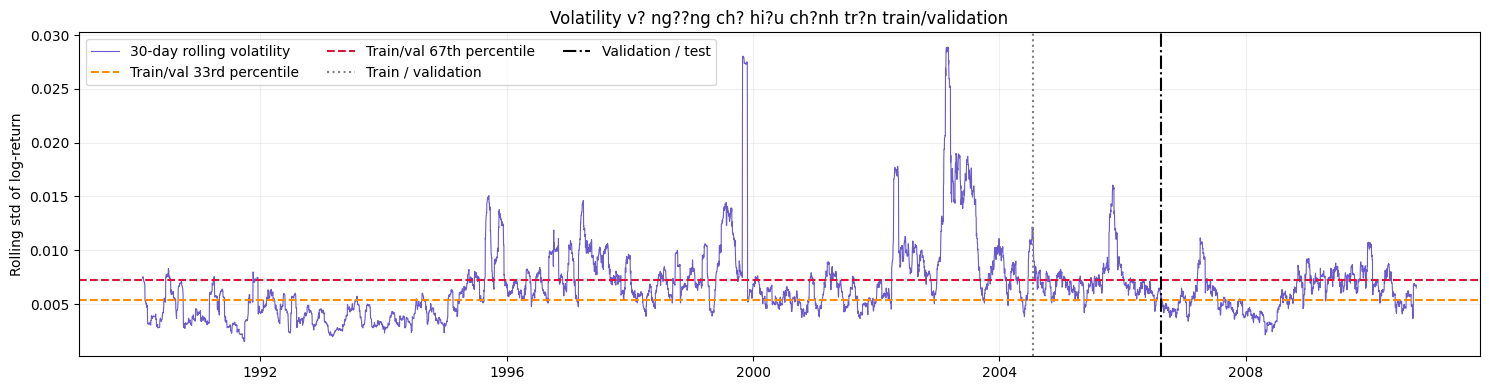

In [2]:
ot = raw["OT"].astype(float)
log_ret = np.log(ot.where(ot > 0)).diff()
vol = log_ret.rolling(VOL_WINDOW, min_periods=VOL_WINDOW).std()
calibration = vol.iloc[:val_end].dropna()  # train + validation only
LOW_HIGH_CUTS = calibration.quantile([1/3, 2/3]).to_numpy()
low_cut, high_cut = LOW_HIGH_CUTS
print(f"Volatility thresholds (train + validation): Low/Medium={low_cut:.8g}; Medium/High={high_cut:.8g}")

# Split indices reproduce Dataset_Custom borders, including seq_len context in val/test.
test_start = val_end - SEQ_LEN
print(f"Test target start row={val_end}; test window context starts row={test_start}")

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(raw["date"], vol, lw=.8, color="slateblue", label="30-day rolling volatility")
ax.axhline(low_cut, color="darkorange", ls="--", label="Train/val 33rd percentile")
ax.axhline(high_cut, color="crimson", ls="--", label="Train/val 67th percentile")
ax.axvline(raw["date"].iloc[train_end], color="gray", ls=":", label="Train / validation")
ax.axvline(raw["date"].iloc[val_end], color="black", ls="-.", label="Validation / test")
ax.set_title("Volatility v? ng??ng ch? hi?u ch?nh tr?n train/validation")
ax.set_ylabel("Rolling std of log-return"); ax.legend(ncol=3); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()


## N?p d? ?o?n, ??i chi?u ground truth v? t?nh sai s?

C?c file gi?a k? l?u d? ?o?n chu?n h?a nh?ng kh?ng l?u `true.npy`. Cell d??i t?i d?ng th? t? timestamp v? target theo Dataset_Custom/test DataLoader; t??ng t? `drop_last=True`, s? forecast origins d?ng ???c l? b?i s? batch 128. Ki?m tra shape ???c th?c hi?n tr??c khi t?nh ch? s?.


In [3]:
# StandardScaler trong Dataset_Custom ???c fit tr?n 70% ??u c?a m?i bi?n.
train_values = raw[cols].iloc[:n_train].to_numpy(dtype=np.float64)
scaler_mean = train_values.mean(axis=0)
scaler_std = train_values.std(axis=0, ddof=0)
ot_idx = cols.index("OT")

all_errors = {}
summary_rows = []
for horizon in PRED_LENGTHS:
    matches = list(PRED_DIR.glob(f"TVCFormer_ExchangeRate_336_{horizon}_*/pred.npy"))
    if len(matches) != 1:
        raise FileNotFoundError(f"Horizon {horizon}: expected one pred.npy, found {len(matches)}")
    pred_scaled = np.load(matches[0])
    if pred_scaled.ndim != 3 or pred_scaled.shape[1:] != (horizon, len(cols)):
        raise ValueError(f"Unexpected prediction shape for {horizon}: {pred_scaled.shape}")
    n_origins = pred_scaled.shape[0]
    # DataLoader test starts at row val_end-seq_len. Target begins after seq_len context.
    target_start = test_start + SEQ_LEN
    target_idx = target_start + np.arange(n_origins)[:, None] + np.arange(horizon)[None, :]
    if target_idx.max() >= n:
        raise ValueError("Reconstructed target indices exceed raw dataset")
    true_scaled = (raw["OT"].to_numpy()[target_idx] - scaler_mean[ot_idx]) / scaler_std[ot_idx]
    pred_ot = pred_scaled[:, :, ot_idx] * scaler_std[ot_idx] + scaler_mean[ot_idx]
    true_ot = true_scaled * scaler_std[ot_idx] + scaler_mean[ot_idx]
    # Forecast origin is the timestamp immediately before first target point.
    origin_idx = target_start - 1 + np.arange(n_origins)
    origin_vol = vol.iloc[origin_idx].to_numpy()
    labels = np.where(origin_vol <= low_cut, "Low", np.where(origin_vol <= high_cut, "Medium", "High"))
    timestamps = raw["date"].to_numpy()[target_idx]
    err = pd.DataFrame({
        "horizon":horizon,
        "origin_index":np.repeat(origin_idx, horizon),
        "origin_date":np.repeat(raw["date"].to_numpy()[origin_idx], horizon),
        "date":timestamps.reshape(-1),
        "lead":np.tile(np.arange(1, horizon+1), n_origins),
        "volatility":np.repeat(origin_vol, horizon),
        "volatility_group":np.repeat(labels, horizon),
        "true":true_ot.reshape(-1),
        "pred":pred_ot.reshape(-1),
    })
    err["error"] = err["pred"] - err["true"]
    err["squared_error"] = err["error"] ** 2
    err["absolute_error"] = err["error"].abs()
    all_errors[horizon] = err
    summary_rows.append({"Pred_len":horizon,"MSE":err["squared_error"].mean(),
                         "MAE":err["absolute_error"].mean(),"Forecast_origins":n_origins,
                         "Forecast_cells":len(err)})

overall = pd.DataFrame(summary_rows)
display(overall.style.format({"MSE":"{:.6f}","MAE":"{:.6f}"}))


,Pred_len,MSE,MAE,Forecast_origins,Forecast_cells
0,96,0.000961,0.022599,1408,135168
1,192,0.001929,0.032656,1280,245760
2,336,0.003892,0.046751,1152,387072
3,720,0.009588,0.076178,768,552960


## Sai s? theo th?i gian

Bi?u ?? cho t?ng horizon: MSE trung b?nh theo forecast origin tr?n to?n b? lead, v? ???ng MAE theo th?i ?i?m ??ch (rolling 30 ng?y). Nh?ng gi? tr? t?i c?ng timestamp ???c t?ng h?p qua c?c origin/lead ?? d? b?o timestamp ??.


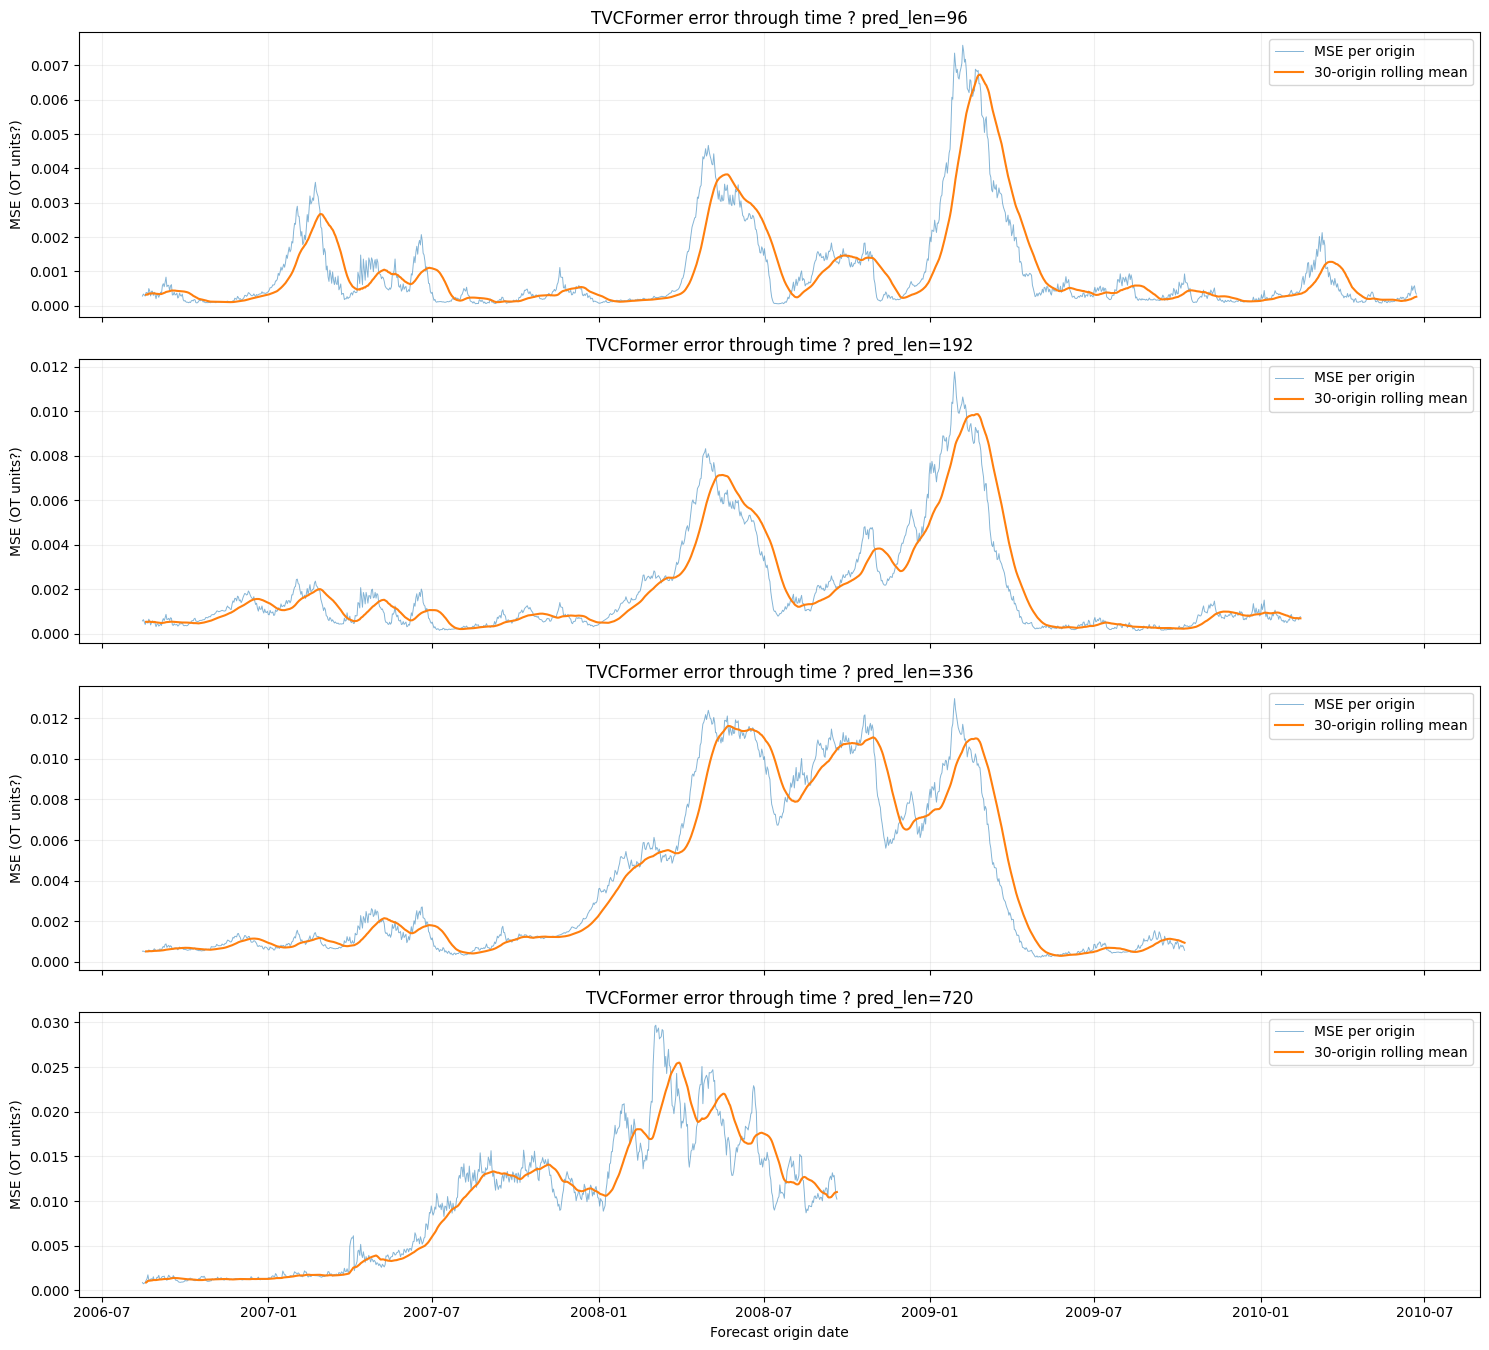

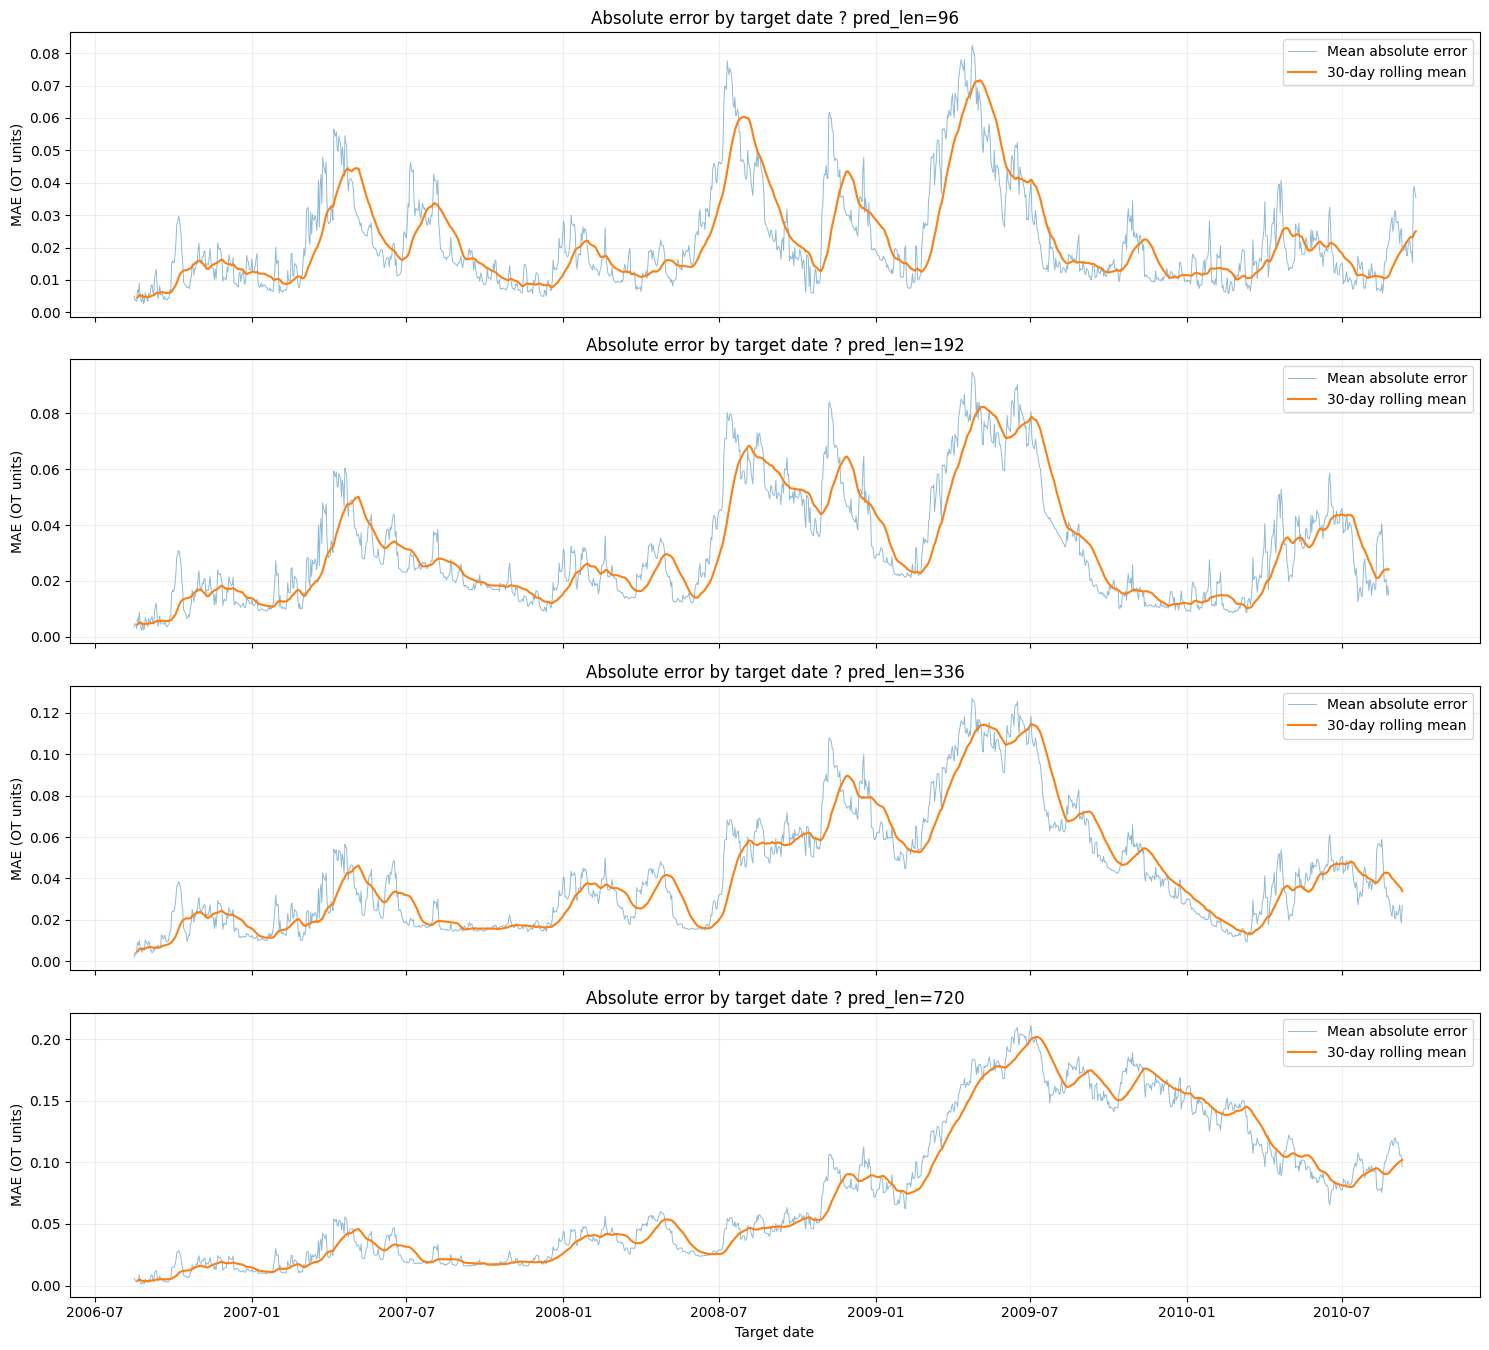

In [4]:
time_rows = []
for horizon, err in all_errors.items():
    by_origin = err.groupby(["origin_index","origin_date"], as_index=False).agg(
        MSE=("squared_error","mean"), MAE=("absolute_error","mean"))
    by_origin["horizon"] = horizon
    time_rows.append(by_origin)
origin_metrics = pd.concat(time_rows, ignore_index=True)

fig, axes = plt.subplots(len(PRED_LENGTHS), 1, figsize=(15, 3.4*len(PRED_LENGTHS)), sharex=True)
for ax, horizon in zip(axes, PRED_LENGTHS):
    g = origin_metrics[origin_metrics.horizon == horizon]
    ax.plot(g.origin_date, g.MSE, lw=.7, alpha=.55, label="MSE per origin")
    ax.plot(g.origin_date, g.MSE.rolling(30, min_periods=5).mean(), lw=1.5, label="30-origin rolling mean")
    ax.set_title(f"TVCFormer error through time ? pred_len={horizon}")
    ax.set_ylabel("MSE (OT units?)"); ax.grid(alpha=.2); ax.legend()
axes[-1].set_xlabel("Forecast origin date"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(len(PRED_LENGTHS), 1, figsize=(15, 3.4*len(PRED_LENGTHS)), sharex=True)
for ax, horizon in zip(axes, PRED_LENGTHS):
    by_date = all_errors[horizon].groupby("date")["absolute_error"].mean().sort_index()
    ax.plot(by_date.index, by_date, lw=.7, alpha=.5, label="Mean absolute error")
    ax.plot(by_date.index, by_date.rolling(30, min_periods=5).mean(), lw=1.5, label="30-day rolling mean")
    ax.set_title(f"Absolute error by target date ? pred_len={horizon}")
    ax.set_ylabel("MAE (OT units)"); ax.grid(alpha=.2); ax.legend()
axes[-1].set_xlabel("Target date"); plt.tight_layout(); plt.show()


## MSE/MAE theo nh?m volatility

B?ng b?o c?o s? forecast cells v? s? forecast origins trong m?i nh?m ?? l?m r? ?? ph?. Nh?m ???c g?n theo volatility t?i forecast origin; ng??ng kh?ng ???c t?i ??c l??ng tr?n test.


,Pred_len,Volatility_Group,MSE,MAE,Forecast_origins,Forecast_cells
0,96,Low,0.000857,0.021236,558,53568
1,96,Medium,0.001141,0.025358,470,45120
2,96,High,0.000893,0.021189,380,36480
3,192,Low,0.001966,0.033583,539,103488
4,192,Medium,0.001963,0.032920,401,76992
5,192,High,0.001830,0.030873,340,65280
6,336,Low,0.004088,0.048017,539,181104
7,336,Medium,0.004339,0.049051,350,117600
8,336,High,0.002897,0.041095,263,88368
9,720,Low,0.011426,0.084633,526,378720


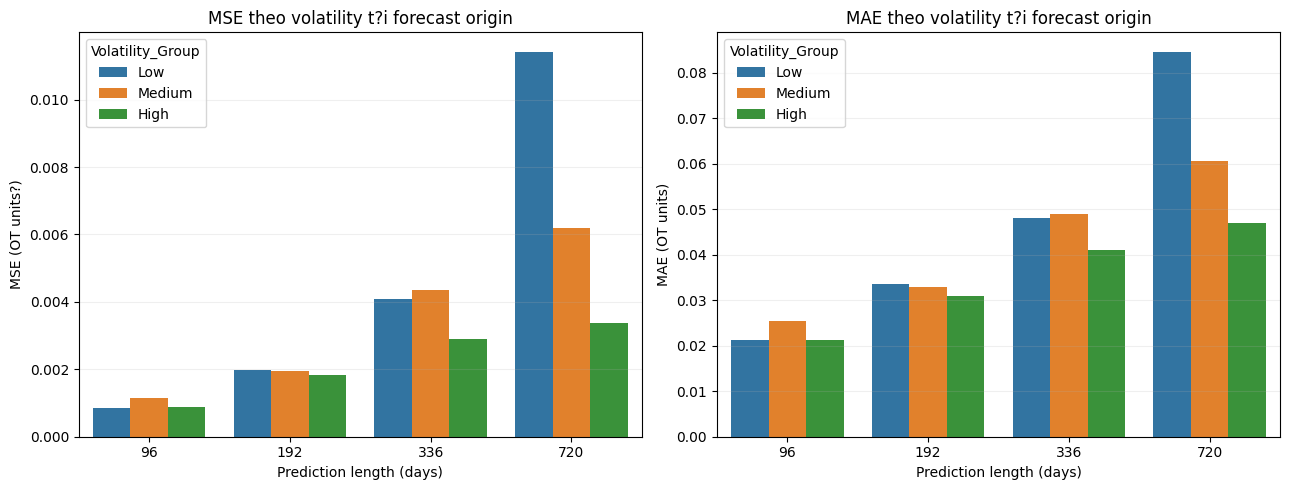

In [5]:
group_rows = []
for horizon, err in all_errors.items():
    for group in ["Low","Medium","High"]:
        g = err[err.volatility_group == group]
        group_rows.append({"Pred_len":horizon,"Volatility_Group":group,
                           "MSE":g.squared_error.mean(),"MAE":g.absolute_error.mean(),
                           "Forecast_origins":g.origin_index.nunique(),"Forecast_cells":len(g)})
group_metrics = pd.DataFrame(group_rows)
display(group_metrics.style.format({"MSE":"{:.6f}","MAE":"{:.6f}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=group_metrics, x="Pred_len", y="MSE", hue="Volatility_Group",
            hue_order=["Low","Medium","High"], ax=axes[0])
axes[0].set_title("MSE theo volatility t?i forecast origin"); axes[0].set_ylabel("MSE (OT units?)")
sns.barplot(data=group_metrics, x="Pred_len", y="MAE", hue="Volatility_Group",
            hue_order=["Low","Medium","High"], ax=axes[1])
axes[1].set_title("MAE theo volatility t?i forecast origin"); axes[1].set_ylabel("MAE (OT units)")
for ax in axes: ax.set_xlabel("Prediction length (days)"); ax.grid(axis="y",alpha=.2)
plt.tight_layout(); plt.show()


## Ghi ch? di?n gi?i

- MSE/MAE t?nh tr?n to?n b? target v? forecast lead ?? l?u, sau khi inverse-transform ri?ng c?t OT.
- M?i horizon c? s? origin kh?c nhau do ?? d?i d? b?o v? `drop_last` c?a DataLoader; xem b?ng t?ng quan.
- Ph?n nh?m volatility d?ng gi? tr? t?i origin, t?c th?ng tin ?? quan s?t tr??c forecast. B?ng ?o sai s? theo ?i?u ki?n th? tr??ng t?i l?c ph?t h?nh d? b?o.
- Ki?m tra s? l??ng nh?m. N?u m?t nh?m kh?ng c? origin v? ph?n ph?i d? li?u kh?c th??ng, c?c ch? s? c?a nh?m ?? s? l? NaN.


In [6]:
coverage = (pd.DataFrame([{"Pred_len":h,"Volatility_Group":k,
                           "Origins":int(v.origin_index.nunique()),"Cells":len(v)}
                          for h,e in all_errors.items()
                          for k,v in e.groupby("volatility_group")])
            .sort_values(["Pred_len","Volatility_Group"]))
display(coverage)
print("Cutoffs were computed from volatility.iloc[:val_end] only; test errors were not used to set them.")


,Pred_len,Volatility_Group,Origins,Cells
0,96,High,380,36480
1,96,Low,558,53568
2,96,Medium,470,45120
3,192,High,340,65280
4,192,Low,539,103488
5,192,Medium,401,76992
6,336,High,263,88368
7,336,Low,539,181104
8,336,Medium,350,117600
9,720,High,51,36720


Cutoffs were computed from volatility.iloc[:val_end] only; test errors were not used to set them.
